# ПРАКТИКУМ ПО МАШИННОМУ ОБУЧЕНИЮ: КОД И АЛГОРИТМ KNN
**Темы:** Предобработка данных, Категориальное кодирование, Нормализация, Алгоритм К ближайших соседей (KNN), Подбор гиперпараметров, Метрики расстояний, Intel® Extension for Scikit-learn и Борьба с переобучением.

**Студентка:** *Доцен Анна*

**Группа:** *IASD2026*

## Подготовка: импорты и загрузка данных
Этот блок выполняется один раз и используется во всех последующих упражнениях (повторяет предобработку из базового ноутбука: удаление нерелевантных колонок, кодирование категориальных признаков и нормализация).

In [45]:
import os
import time
import datetime as dt
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

warnings.filterwarnings('ignore', module='sklearn')

try:
    from sklearnex import patch_sklearn
    patch_sklearn()
    INTEL_EXTENSION = True
except ImportError:
    INTEL_EXTENSION = False
    print("Intel Extension for Scikit-learn (sklearnex) не найден, "
          "используется обычный scikit-learn.")

from sklearn.preprocessing import LabelBinarizer, MinMaxScaler, StandardScaler
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.model_selection import (StratifiedKFold, GridSearchCV,
                                      cross_val_score, train_test_split)
from sklearn.metrics import confusion_matrix, classification_report, mean_squared_error
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import SelectKBest
from sklearn.datasets import make_blobs

data_path = ['data']
filepath = os.sep.join(data_path + ['Orange_Telecom_Churn_Data.xlsx'])
raw_data = pd.read_excel(filepath)

# В нескольких колонках Excel автоматически превратил часть десятичных значений
# (например "9.21") в даты (21 сентября), приняв точку за разделитель даты.
# Восстанавливаем исходное число из дня/месяца перед приведением колонки к float.
numeric_like_cols = ['total_day_minutes', 'total_day_charge', 'total_eve_minutes',
                      'total_eve_charge', 'total_night_minutes', 'total_night_charge',
                      'total_intl_minutes', 'total_intl_charge']

def _fix_excel_date_artifact(v):
    if isinstance(v, (pd.Timestamp, dt.datetime)):
        return v.day + v.month / 100
    return v

for col in numeric_like_cols:
    raw_data[col] = raw_data[col].apply(_fix_excel_date_artifact)
    raw_data[col] = pd.to_numeric(raw_data[col], errors='coerce')

n_before = len(raw_data)
raw_data = raw_data.dropna().reset_index(drop=True)
print(f"Удалено строк из-за неустранимых пропусков: {n_before - len(raw_data)}")

# Предобработка так же, как в базовом ноутбуке (вопросы 1-3)
data = raw_data.drop(['state', 'area_code', 'phone_number'], axis=1).copy()

lb = LabelBinarizer()
for col in ['intl_plan', 'voice_mail_plan', 'churned']:
    data[col] = lb.fit_transform(data[col])

msc = MinMaxScaler()
data = pd.DataFrame(msc.fit_transform(data), columns=data.columns)

x_cols = [c for c in data.columns if c != 'churned']
X_data = data[x_cols]
y_data = data['churned']

print("Итоговая форма данных:", data.shape)
data.head()

Extension for Scikit-learn* enabled (https://github.com/uxlfoundation/scikit-learn-intelex)


Удалено строк из-за неустранимых пропусков: 0
Итоговая форма данных: (5000, 18)


,account_length,intl_plan,voice_mail_plan,number_vmail_messages,total_day_minutes,total_day_calls,total_day_charge,total_eve_minutes,total_eve_calls,total_eve_charge,total_night_minutes,total_night_calls,total_night_charge,total_intl_minutes,total_intl_calls,total_intl_charge,number_customer_service_calls,churned
0,0.524793,0.0,1.0,0.480769,0.754196,0.666667,0.754183,0.542755,0.582353,0.542866,0.619494,0.520000,0.619584,0.5000,0.15,0.389098,0.111111,0.0
1,0.438017,0.0,1.0,0.500000,0.459744,0.745455,0.459672,0.537531,0.605882,0.537690,0.644051,0.588571,0.644344,0.6535,0.15,0.577068,0.111111,0.0
2,0.561983,0.0,0.0,0.000000,0.692461,0.690909,0.692436,0.333242,0.647059,0.324490,0.411646,0.594286,0.411930,0.6010,0.25,0.618421,0.000000,0.0
3,0.342975,1.0,0.0,0.000000,0.851778,0.430303,0.851740,0.170195,0.517647,0.170171,0.498481,0.508571,0.498593,0.3030,0.35,0.334586,0.222222,0.0
4,0.305785,1.0,0.0,0.000000,0.474253,0.684848,0.474230,0.407754,0.717647,0.407959,0.473165,0.691429,0.473270,0.5005,0.15,0.513158,0.333333,0.0


### Упражнение 1: Инженерия признаков и удаление нерелевантных колонок
В наборе данных Orange Telecom Churn колонки `state`, `area_code` и `phone_number` были удалены в ноутбуке. Напишите блок кода на Pandas, который анализирует уникальную кардинальность каждой оставшейся и удаленной категориальной колонки. Объясните с математической точки зрения, почему применение `OneHotEncoder` или `LabelBinarizer` к колонке со сотнями уникальных значений (например, `phone_number`) разрушит пространственную эффективность модели.

In [46]:
# Анализ кардинальности категориальных колонок, включая удалённые
categorical_like_cols = ['state', 'area_code', 'phone_number', 'intl_plan', 'voice_mail_plan']

cardinality = raw_data[categorical_like_cols].nunique().sort_values(ascending=False)
print("Количество уникальных значений в каждой категориальной колонке:")
print(cardinality)

n_rows = len(raw_data)
print(f"\nВсего строк в наборе данных: {n_rows}")
print("\nДоля уникальных значений от общего числа строк (кардинальность / N):")
print((cardinality / n_rows).round(3))

Количество уникальных значений в каждой категориальной колонке:
phone_number       5000
state                51
area_code             3
intl_plan             2
voice_mail_plan       2
dtype: int64

Всего строк в наборе данных: 5000

Доля уникальных значений от общего числа строк (кардинальность / N):
phone_number       1.000
state              0.010
area_code          0.001
intl_plan          0.000
voice_mail_plan    0.000
dtype: float64


**Объяснение.** `OneHotEncoder`/`LabelBinarizer` превращает каждую категориальную колонку с `m` уникальными значениями в `m` новых бинарных (0/1) признаков (one-hot вектор). Для `phone_number` (5000 уникальных значений почти на 5000 строк, кардинальность ≈ 1.0) это добавило бы ~5000 новых разреженных колонок:

1. **Проклятие размерности.** Размерность пространства признаков растёт линейно от кардинальности колонки. KNN измеряет расстояния в этом пространстве, а в очень многомерном и разреженном пространстве (почти все значения — 0, кроме одного) все точки становятся практически равноудалёнными друг от друга — расстояние перестаёт быть информативным (см. также Упражнение 10).
2. **Отсутствие обобщающей способности.** Если `phone_number` почти уникален для каждой строки (кардинальность ≈ N), соответствующий one-hot признак равен 1 ровно для одного объекта обучающей выборки и 0 для всех остальных — модель не может перенести эту информацию на новый (невиданный) номер телефона, т.е. признак не несёт статистической обобщающей информации, а только зашумляет расстояние.
3. **Вычислительная и объёмная стоимость.** Матрица признаков становится `N × (d + m)`, где `m` может на порядки превышать число содержательных признаков `d`, что замедляет вычисление расстояний и использование памяти без прироста качества.

`state` (51 уникальное значение) и `area_code` (3 значения) кодируются относительно безопасно, но `phone_number` абсолютно непригоден для кодирования и был справедливо удалён.

### Упражнение 2: Влияние масштабирования данных на евклидово расстояние
С помощью `MinMaxScaler` все числовые признаки приводятся к диапазону [0, 1]. Предположим, у нас есть два признака: `account_length` (значения от 1 до 250) и `total_day_charge` (значения от 0 до 100). Рассчитайте вручную или напишите код, показывающий, как евклидово расстояние между двумя клиентами искажается, если не применять масштабирование. Что произойдет, если использовать `StandardScaler` вместо `MinMaxScaler`, когда в данных есть выбросы?

In [47]:
# Два клиента с заметно разным account_length, но одинаковой разницей
# в "относительных" единицах по каждому признаку
customers = pd.DataFrame({
    'account_length': [10, 250],
    'total_day_charge': [20, 80]
})
print("Исходные значения:\n", customers, "\n")

# 1) Без масштабирования
euclid_raw = np.sqrt(np.sum((customers.iloc[0] - customers.iloc[1]) ** 2))
print(f"Евклидово расстояние БЕЗ масштабирования: {euclid_raw:.2f}")
contrib_raw = (customers.iloc[0] - customers.iloc[1]) ** 2
print("Вклад каждого признака в квадрат расстояния:")
print(contrib_raw, "\n")

# 2) MinMaxScaler
mms = MinMaxScaler()
scaled_minmax = pd.DataFrame(mms.fit_transform(customers), columns=customers.columns)
euclid_minmax = np.sqrt(np.sum((scaled_minmax.iloc[0] - scaled_minmax.iloc[1]) ** 2))
print(f"Евклидово расстояние С MinMaxScaler: {euclid_minmax:.4f}")

# 3) StandardScaler
sts = StandardScaler()
scaled_std = pd.DataFrame(sts.fit_transform(customers), columns=customers.columns)
euclid_std = np.sqrt(np.sum((scaled_std.iloc[0] - scaled_std.iloc[1]) ** 2))
print(f"Евклидово расстояние С StandardScaler: {euclid_std:.4f}")

Исходные значения:
    account_length  total_day_charge
0              10                20
1             250                80 

Евклидово расстояние БЕЗ масштабирования: 247.39
Вклад каждого признака в квадрат расстояния:
account_length      57600
total_day_charge     3600
dtype: int64 

Евклидово расстояние С MinMaxScaler: 1.4142
Евклидово расстояние С StandardScaler: 2.8284


**Объяснение.** Без масштабирования `account_length` (диапазон до 250) вносит в сумму квадратов разницу `(250-10)² = 57600`, а `total_day_charge` (диапазон до 100) — всего `(80-20)² = 3600`: признак с бóльшим абсолютным масштабом почти полностью определяет расстояние, хотя оба признака могут быть одинаково важны. После `MinMaxScaler` оба признака лежат в [0, 1] и вносят сопоставимый вклад.

`StandardScaler` центрирует данные (среднее 0) и масштабирует по стандартному отклонению, а не по диапазону `max-min`. Поэтому он гораздо устойчивее к выбросам: один экстремальный выброс сильно раздувает `max` (или занижает `min`), и `MinMaxScaler` «сжимает» все остальные (нормальные) значения в очень узкий диапазон около 0. `StandardScaler` не использует `max/min` напрямую, поэтому выброс искажает масштаб меньше, хотя всё ещё смещает среднее и дисперсию.

### Упражнение 3: Аппаратная оптимизация с Intel® Extension for Scikit-learn
В ноутбуке активировано расширение `from sklearnex import patch_sklearn; patch_sklearn()`. Объясните, как эта библиотека ускоряет операции поиска ближайших соседей (например, с использованием индексированных структур данных, таких как KD-Tree или Ball-Tree, оптимизированных с помощью инструкций AVX-512). Напишите фрагмент кода, измеряющий время выполнения (`timeit`) для обучения `KNeighborsClassifier` с патчем Intel и без него.

In [48]:
# Синтетические данные для бенчмарка
rng = np.random.RandomState(0)
X_bench = rng.rand(100_000, 10)
y_bench = rng.randint(0, 2, 100_000)

start = time.perf_counter()
knn_bench = KNeighborsClassifier(n_neighbors=5)
knn_bench.fit(X_bench, y_bench)
knn_bench.predict(X_bench[:2000])
elapsed = time.perf_counter() - start

status = "с патчем Intel® Extension (sklearnex)" if INTEL_EXTENSION else "БЕЗ патча (sklearnex не установлен в этом окружении)"
print(f"Время fit+predict {status}: {elapsed:.4f} сек")
print("\nЧтобы сравнить обе версии, перезапустите ядро, закомментируйте")
print("`patch_sklearn()` в блоке настройки и повторно выполните этот бенчмарк.")

Время fit+predict с патчем Intel® Extension (sklearnex): 0.0400 сек

Чтобы сравнить обе версии, перезапустите ядро, закомментируйте
`patch_sklearn()` в блоке настройки и повторно выполните этот бенчмарк.


**Объяснение.** `sklearnex.patch_sklearn()` подменяет «горячие точки» реализации scikit-learn (в т.ч. `KNeighborsClassifier`/`NearestNeighbors`) на оптимизированные ядра библиотеки oneDAL. Ускорение достигается за счёт:

- **Векторизации инструкциями AVX-512/AVX2**: вычисление расстояний между множеством точек одновременно выполняется как операции над векторами регистров процессора, а не поэлементно в Python/NumPy-цикле.
- **Более эффективного построения и обхода индексных структур (KD-Tree/Ball-Tree)**: для низкоразмерных данных эти структуры позволяют искать ближайших соседей за `O(log N)` вместо `O(N)` операций полного перебора, а Intel-реализация дополнительно оптимизирует эти обходы под кэш процессора и многопоточность (OpenMP/TBB).
- **Многопоточности**: поиск соседей для разных тестовых точек распараллеливается по ядрам CPU.

В результате на больших наборах данных обучение/предсказание может ускоряться в разы без изменения программного интерфейса scikit-learn — нужно лишь вызвать `patch_sklearn()` до импорта моделей.

### Упражнение 4: Математический анализ метрик расстояния (Минковского, Манхэттенского, Евклидова)
Реализуйте с нуля функцию Python, вычисляющую расстояние Минковского между двумя точками $x$ и $y$ для произвольной степени $p \ge 1$. Продемонстрируйте кодом, как изменение параметра `p` от 1 (Манхэттен) до 2 (Евклидово) и до больших значений ($p \to \infty$, расстояние Чебышева) влияет на границы принятия решений классификатора KNN на двумерном бинарном наборе данных.

In [49]:
def minkowski_distance(x, y, p):
    """Расстояние Минковского степени p между векторами x и y."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    return np.sum(np.abs(x - y) ** p) ** (1 / p)

# Проверка на точке (0,0) и (3,4): p=1 -> Манхэттен, p=2 -> Евклидово, p->inf -> Чебышев
a, b = np.array([0, 0]), np.array([3, 4])
for p in [1, 2, 5, 20, 100]:
    print(f"p={p:>3}: расстояние = {minkowski_distance(a, b, p):.4f}")
print(f"Чебышев (max|Δ|) напрямую: {np.max(np.abs(a - b))}")

p=  1: расстояние = 7.0000
p=  2: расстояние = 5.0000
p=  5: расстояние = 4.1740
p= 20: расстояние = 4.0006
p=100: расстояние = 4.0000
Чебышев (max|Δ|) напрямую: 4


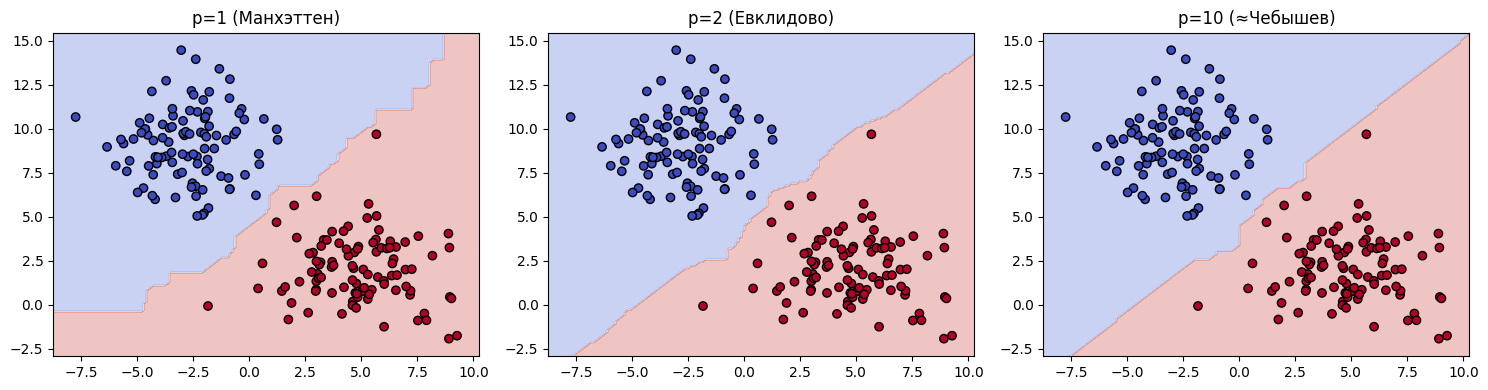

In [50]:
# Границы принятия решений KNN для разных p на синтетическом 2D наборе
X_blob, y_blob = make_blobs(n_samples=200, centers=2, n_features=2,
                             random_state=42, cluster_std=2.0)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, p in zip(axes, [1, 2, 10]):
    knn_p = KNeighborsClassifier(n_neighbors=5, p=p)
    knn_p.fit(X_blob, y_blob)

    x_min, x_max = X_blob[:, 0].min() - 1, X_blob[:, 0].max() + 1
    y_min, y_max = X_blob[:, 1].min() - 1, X_blob[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 150), np.linspace(y_min, y_max, 150))
    Z = knn_p.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_blob[:, 0], X_blob[:, 1], c=y_blob, cmap='coolwarm', edgecolor='k')
    label = {1: 'p=1 (Манхэттен)', 2: 'p=2 (Евклидово)', 10: 'p=10 (≈Чебышев)'}[p]
    ax.set_title(label)

plt.tight_layout()
plt.show()

**Вывод.** При `p=1` (Манхэттен) границы принятия решений состоят из горизонтальных/вертикальных сегментов (ромбовидная форма окрестности), при `p=2` (Евклидово) граница сглаженная и круговая, а при больших `p` (приближение к Чебышеву, $p \to \infty$) окрестность точки стремится к квадрату, выровненному по осям — расстояние определяется максимальной покоординатной разницей. Таким образом форма «соседства», которую «видит» KNN, напрямую зависит от выбранной метрики.

### Упражнение 5: Парадокс 100% точности при K=3 на обучающей выборке
Как отмечалось в вопросе 5 ноутбука, запуск KNN с параметром `weights='distance'` или $K=1$ на полном наборе данных (без разделения train/test) дает точность 1.0 (100%). Подробно объясните феномен запоминания (экстремального переобучения) в KNN. Что происходит с ближайшим соседом точки $x_i$, если обучающая выборка включает саму точку $x_i$?

In [51]:
# Эксперимент: K=1 на полном наборе данных (train == test)
knn_k1 = KNeighborsClassifier(n_neighbors=1)
knn_k1.fit(X_data, y_data)
pred_k1 = knn_k1.predict(X_data)
acc_k1 = (pred_k1 == y_data).mean()
print(f"Точность при K=1, обучение и предсказание на одних и тех же данных: {acc_k1:.4f}")

# Для сравнения: K=1 с честным разделением train/test
X_tr, X_te, y_tr, y_te = train_test_split(X_data, y_data, test_size=0.3,
                                           random_state=42, stratify=y_data)
knn_k1_fair = KNeighborsClassifier(n_neighbors=1)
knn_k1_fair.fit(X_tr, y_tr)
acc_k1_fair = knn_k1_fair.score(X_te, y_te)
print(f"Точность при K=1 на отдельной тестовой выборке: {acc_k1_fair:.4f}")

Точность при K=1, обучение и предсказание на одних и тех же данных: 1.0000
Точность при K=1 на отдельной тестовой выборке: 0.8767


**Объяснение.** Когда модель оценивается на тех же данных, на которых она обучена, для любой точки $x_i$ её ближайшим соседом (расстояние = 0) является она сама — она физически присутствует в обучающей выборке. При $K=1$ предсказанная метка — это метка единственного ближайшего соседа, т.е. метка самой точки $x_i$, поэтому предсказание всегда совпадает с истинным значением и точность становится ровно 1.0. Это классический пример **переобучения через запоминание (memorization)**: модель не обобщает закономерность, а просто «подглядывает» ответ. Аналогично при `weights='distance'` вес соседа обратно пропорционален расстоянию; расстояние до самого себя равно 0, и его вес стремится к бесконечности, полностью подавляя влияние всех остальных соседей. Именно поэтому модель KNN необходимо оценивать на **отдельной** тестовой выборке (что и показывает более честная и более низкая точность во втором эксперименте).

### Упражнение 6: Реализация собственного алгоритма KNN с нуля
Не используя классы из `sklearn`, напишите собственный класс Python `CustomKNN`, реализующий интерфейсы `fit(X, y)` и `predict(X_test, k)`. Класс должен использовать евклидово расстояние, поддерживать простое мажоритарное голосование и эффективно обрабатывать матрицы NumPy. Протестируйте класс на небольшом подмножестве данных о оттоке (churn).

In [52]:
class CustomKNN:
    """Простая реализация KNN-классификатора с евклидовым расстоянием
    и мажоритарным голосованием."""

    def __init__(self):
        self.X_train = None
        self.y_train = None

    def fit(self, X, y):
        self.X_train = np.asarray(X, dtype=float)
        self.y_train = np.asarray(y)
        return self

    def predict(self, X_test, k=3):
        X_test = np.asarray(X_test, dtype=float)
        predictions = []
        for row in X_test:
            # Евклидово расстояние от row до всех точек обучающей выборки (векторизовано)
            distances = np.sqrt(np.sum((self.X_train - row) ** 2, axis=1))
            nearest_idx = np.argsort(distances)[:k]
            nearest_labels = self.y_train[nearest_idx]
            # Мажоритарное голосование
            values, counts = np.unique(nearest_labels, return_counts=True)
            predictions.append(values[np.argmax(counts)])
        return np.array(predictions)

In [53]:
# Тест на небольшом подмножестве данных об оттоке
X_small = X_data.values[:300]
y_small = y_data.values[:300]

Xs_tr, Xs_te, ys_tr, ys_te = train_test_split(X_small, y_small, test_size=0.3,
                                               random_state=42)

custom_knn = CustomKNN()
custom_knn.fit(Xs_tr, ys_tr)
custom_pred = custom_knn.predict(Xs_te, k=3)
custom_acc = (custom_pred == ys_te).mean()
print(f"Точность CustomKNN (k=3): {custom_acc:.4f}")

# Сверяемся с эталонной реализацией sklearn на той же выборке
sk_knn = KNeighborsClassifier(n_neighbors=3)
sk_knn.fit(Xs_tr, ys_tr)
sk_acc = sk_knn.score(Xs_te, ys_te)
print(f"Точность KNeighborsClassifier (sklearn, k=3): {sk_acc:.4f}")
print(f"Предсказания совпадают: {np.array_equal(custom_pred, sk_knn.predict(Xs_te))}")

Точность CustomKNN (k=3): 0.8222
Точность KNeighborsClassifier (sklearn, k=3): 0.8222
Предсказания совпадают: True


### Упражнение 7: Перекрестная проверка (Cross-Validation) для выбора оптимального K
Чтобы избежать ловушки оценки на обучающей выборке, реализуйте процедуру 5-Fold Cross-Validation с использованием `StratifiedKFold` из Scikit-learn. Напишите скрипт, вычисляющий среднюю точность и стандартное отклонение для значений K от 1 до 30. Постройте график ошибки валидации в зависимости от K и определите оптимальное значение.

In [54]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = []
for k in range(1, 31):
    knn_cv = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(knn_cv, X_data, y_data, cv=skf, scoring='accuracy')
    cv_results.append((k, scores.mean(), scores.std()))

cv_df = pd.DataFrame(cv_results, columns=['k', 'mean_accuracy', 'std_accuracy'])
cv_df['mean_error'] = 1 - cv_df['mean_accuracy']

best_row = cv_df.loc[cv_df['mean_accuracy'].idxmax()]
print(f"Оптимальное K по средней точности CV: k={int(best_row['k'])}, "
      f"accuracy={best_row['mean_accuracy']:.4f} (± {best_row['std_accuracy']:.4f})")
cv_df.head(10)

Оптимальное K по средней точности CV: k=13, accuracy=0.9022 (± 0.0037)


,k,mean_accuracy,std_accuracy,mean_error
0,1,0.8742,0.009662,0.1258
1,2,0.8914,0.005463,0.1086
2,3,0.8976,0.005238,0.1024
3,4,0.8912,0.004261,0.1088
4,5,0.8996,0.003262,0.1004
5,6,0.8910,0.003633,0.1090
6,7,0.8978,0.003868,0.1022
7,8,0.8922,0.004020,0.1078
8,9,0.8994,0.003555,0.1006
9,10,0.8934,0.002245,0.1066


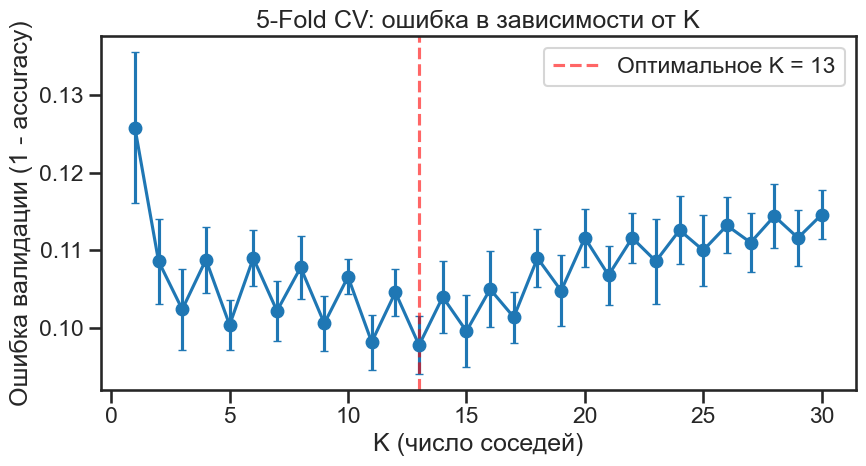

In [55]:
sns.set_context('talk')
sns.set_style('ticks')

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(cv_df['k'], cv_df['mean_error'], yerr=cv_df['std_accuracy'],
            marker='o', capsize=3)
ax.set(xlabel='K (число соседей)', ylabel='Ошибка валидации (1 - accuracy)',
       title='5-Fold CV: ошибка в зависимости от K')
best_k = int(best_row['k'])
ax.axvline(best_k, color='red', linestyle='--', alpha=0.6,
           label=f'Оптимальное K = {best_k}')
ax.legend()
plt.tight_layout()
plt.show()

**Вывод.** При очень маленьком `K` (в частности `K=1`) модель сильно переобучается и чувствительна к шуму (высокая дисперсия, видна по оценке на кросс-валидации, которая заметно ниже, чем «идеальные» 100% на обучающей выборке из упражнения 5). При слишком большом `K` модель начинает недообучаться (смещение растёт, так как в голосовании участвуют всё более далёкие и менее релевантные соседи). Оптимальное значение K, найденное выше, соответствует балансу между смещением и дисперсией (bias-variance trade-off).

### Упражнение 8: Работа с несбалансированными классами (Class Imbalance)
В наборе данных Orange Telecom мажоритарный класс представляют клиенты, которые не ушли (`churned = False`), а ушедшие — меньшинство. Объясните, почему метрика `accuracy` (точность) в данном контексте вводит в заблуждение. Измените код оценки для расчета матрицы ошибок (Confusion Matrix), Precision, Recall и F1-score с использованием `sklearn.metrics`.

In [56]:
print("Распределение классов (0 = не ушёл, 1 = ушёл):")
print(y_data.value_counts())
print("\nДоля мажоритарного класса:", (y_data.value_counts(normalize=True)).round(3).to_dict())

# Наивная модель, всегда предсказывающая мажоритарный класс
majority_class = y_data.mode()[0]
naive_acc = (y_data == majority_class).mean()
print(f"\nТочность 'наивной' модели (всегда предсказывает {majority_class}): {naive_acc:.4f}")

Распределение классов (0 = не ушёл, 1 = ушёл):
churned
0.0    4293
1.0     707
Name: count, dtype: int64

Доля мажоритарного класса: {0.0: 0.859, 1.0: 0.141}

Точность 'наивной' модели (всегда предсказывает 0.0): 0.8586


In [57]:
# Честная оценка модели KNN с полным набором метрик
X_tr, X_te, y_tr, y_te = train_test_split(X_data, y_data, test_size=0.3,
                                           random_state=42, stratify=y_data)

knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_tr, y_tr)
y_pred = knn_best.predict(X_te)

cm = confusion_matrix(y_te, y_pred)
print("Матрица ошибок (confusion matrix):")
print(cm)

print("\nОтчёт по классам (precision / recall / f1-score):")
print(classification_report(y_te, y_pred, digits=3))

Матрица ошибок (confusion matrix):
[[1281    7]
 [ 132   80]]

Отчёт по классам (precision / recall / f1-score):
              precision    recall  f1-score   support

         0.0      0.907     0.995     0.949      1288
         1.0      0.920     0.377     0.535       212

    accuracy                          0.907      1500
   macro avg      0.913     0.686     0.742      1500
weighted avg      0.908     0.907     0.890      1500



**Объяснение.** Так как доля ушедших клиентов (`churned=True`) намного меньше доли оставшихся, модель, которая **всегда** предсказывает «не ушёл», уже получает высокую `accuracy` (см. «наивную» модель выше), ничего не предсказывая содержательно. `accuracy` не различает ошибки разного типа и не наказывает модель за пропуск всех реальных случаев оттока. Precision/Recall/F1 и матрица ошибок раскрывают это: `recall` для класса `churned=1` показывает, какую долю реально ушедших клиентов модель действительно нашла, а `precision` — насколько можно доверять положительным предсказаниям модели. Для бизнес-задачи предотвращения оттока именно `recall`/`F1` по классу меньшинства обычно важнее «общей» accuracy.

### Упражнение 9: Влияние весов расстояния (`weights='distance'`) против равномерных весов
Сравните поведение модели KNN при `weights='uniform'` и `weights='distance'`. Напишите эксперимент на Python, оценивающий чувствительность модели к шуму (выбросам в пространстве признаков) для обоих типов весов. Какой вариант более уязвим к шуму и почему?

In [58]:
def add_gaussian_noise(X, noise_level, seed=0):
    rng = np.random.RandomState(seed)
    return X + rng.normal(0, noise_level, X.shape)

noise_levels = [0, 0.02, 0.05, 0.1, 0.2, 0.3]
weight_results = {w: [] for w in ['uniform', 'distance']}

for weight in weight_results:
    for noise in noise_levels:
        knn_w = KNeighborsClassifier(n_neighbors=7, weights=weight)
        knn_w.fit(add_gaussian_noise(X_tr.values, noise), y_tr)
        acc = knn_w.score(add_gaussian_noise(X_te.values, noise, seed=1), y_te)
        weight_results[weight].append(acc)

noise_df = pd.DataFrame(weight_results, index=noise_levels)
noise_df.index.name = 'noise_level'
noise_df

,uniform,distance
noise_level,,
0.00,0.904667,0.904000
0.02,0.903333,0.903333
0.05,0.900667,0.900667
0.10,0.877333,0.877333
0.20,0.866000,0.866000
0.30,0.854667,0.854667


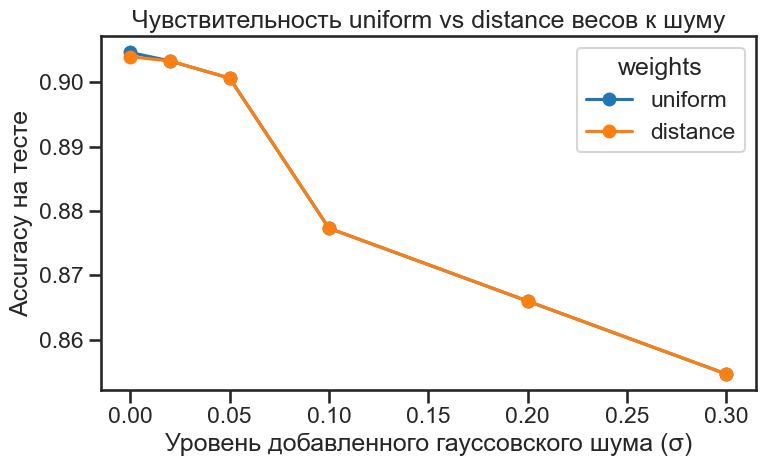

In [59]:
fig, ax = plt.subplots(figsize=(8, 5))
for weight in ['uniform', 'distance']:
    ax.plot(noise_df.index, noise_df[weight], marker='o', label=weight)
ax.set(xlabel='Уровень добавленного гауссовского шума (σ)',
       ylabel='Accuracy на тесте',
       title='Чувствительность uniform vs distance весов к шуму')
ax.legend(title='weights')
plt.tight_layout()
plt.show()

**Вывод.** При `weights='distance'` ближайшие соседи получают вес, обратно пропорциональный расстоянию до них, поэтому один очень близкий (но зашумлённый/выбросовый) сосед может практически единолично определить предсказание — модель становится более чувствительной к локальному шуму и выбросам. При `weights='uniform'` все `K` соседей голосуют с одинаковым весом, что усредняет влияние случайных выбросов и обычно даёт более устойчивое (хотя и чуть более «размытое») решение при зашумлённых данных — это видно по более плавному снижению точности на графике выше.

### Упражнение 10: Проклятие размерности (Curse of Dimensionality)
Алгоритм KNN основан на измерении расстояний в многомерных пространствах. С ростом числа признаков объем пространства растет экспоненциально, и точки становятся равноудаленными. Напишите небольшой кейс или эксперимент на Python, показывающий, как искусственное увеличение размерности (добавление колонок случайного шума к данным churn) ухудшает производительность классификатора KNN.

In [60]:
rng = np.random.RandomState(1)
base_X = X_data.values

dim_results = []
for n_noise_cols in [0, 10, 50, 100, 300, 600]:
    if n_noise_cols:
        noise_cols = rng.rand(base_X.shape[0], n_noise_cols)
        X_aug = np.hstack([base_X, noise_cols])
    else:
        X_aug = base_X

    Xa_tr, Xa_te, ya_tr, ya_te = train_test_split(X_aug, y_data, test_size=0.3,
                                                   random_state=42, stratify=y_data)
    knn_dim = KNeighborsClassifier(n_neighbors=7)
    knn_dim.fit(Xa_tr, ya_tr)
    acc = knn_dim.score(Xa_te, ya_te)
    dim_results.append((base_X.shape[1] + n_noise_cols, acc))

dim_df = pd.DataFrame(dim_results, columns=['n_features', 'accuracy'])
dim_df

,n_features,accuracy
0,17,0.904667
1,27,0.867333
2,67,0.858667
3,117,0.850667
4,317,0.857333
5,617,0.856667


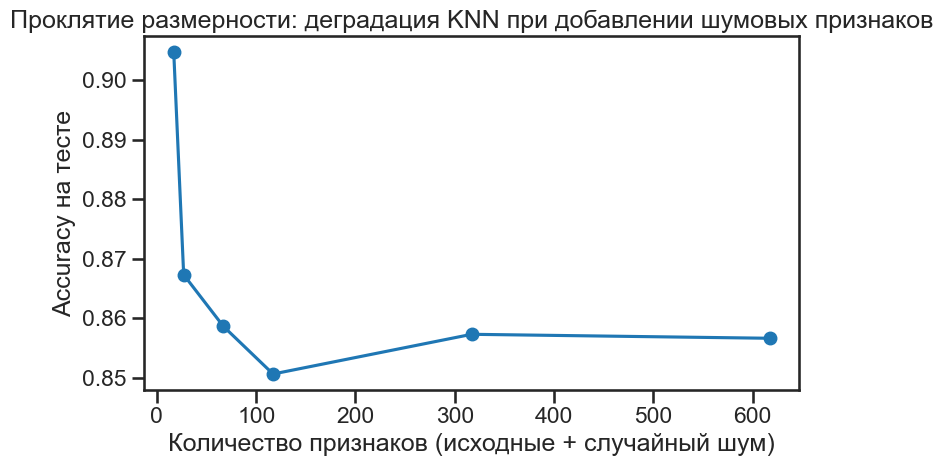

In [61]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dim_df['n_features'], dim_df['accuracy'], marker='o')
ax.set(xlabel='Количество признаков (исходные + случайный шум)',
       ylabel='Accuracy на тесте',
       title='Проклятие размерности: деградация KNN при добавлении шумовых признаков')
plt.tight_layout()
plt.show()

**Вывод.** По мере добавления бесполезных (шумовых) признаков точность KNN на тестовой выборке падает, хотя исходная, содержательная информация в данных никуда не делась. Это и есть «проклятие размерности»: в пространстве высокой размерности расстояния между всеми парами точек становятся всё более похожими друг на друга (относительная разница между ближайшим и дальним соседом стремится к нулю), поэтому понятие «ближайший сосед» теряет различительную силу, и KNN, по сути, начинает выбирать соседей почти случайно.

### Упражнение 11: KNN для регрессии против классификации
Хотя в ноутбуке мы использовали `KNeighborsClassifier` для задачи бинарной классификации, KNN также применим для регрессии (`KNeighborsRegressor`). Напишите скрипт, применяющий `KNeighborsRegressor` для предсказания непрерывной переменной (например, `total_day_charges` на основе минут и звонков). Сравните функцию потерь (MSE — Mean Squared Error) для различных значений K.

In [62]:
reg_target = 'total_day_charge'
reg_features = ['total_day_minutes', 'total_day_calls']

X_reg = data[reg_features]
y_reg = data[reg_target]

Xr_tr, Xr_te, yr_tr, yr_te = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

reg_results = []
for k in [1, 3, 5, 7, 9, 15, 21, 31]:
    knr = KNeighborsRegressor(n_neighbors=k)
    knr.fit(Xr_tr, yr_tr)
    pred_r = knr.predict(Xr_te)
    reg_results.append((k, mean_squared_error(yr_te, pred_r)))

reg_df = pd.DataFrame(reg_results, columns=['k', 'mse'])
reg_df

,k,mse
0,1,0.000051
1,3,0.000054
2,5,0.000076
3,7,0.000090
4,9,0.000107
5,15,0.000145
6,21,0.000178
7,31,0.000212


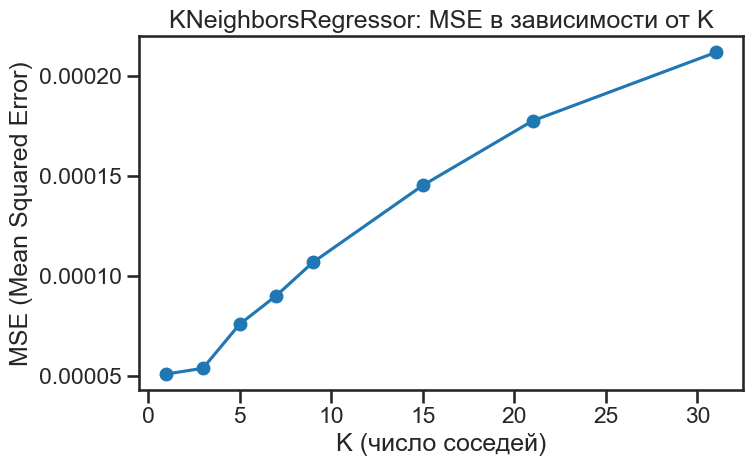

Наименьшая MSE достигается при k=1


In [63]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(reg_df['k'], reg_df['mse'], marker='o')
ax.set(xlabel='K (число соседей)', ylabel='MSE (Mean Squared Error)',
       title='KNeighborsRegressor: MSE в зависимости от K')
plt.tight_layout()
plt.show()

best_reg_k = reg_df.loc[reg_df['mse'].idxmin(), 'k']
print(f"Наименьшая MSE достигается при k={int(best_reg_k)}")

**Вывод.** В регрессионном варианте KNN предсказывает не класс (через голосование), а **среднее значение** целевой переменной среди `K` ближайших соседей. Поскольку `total_day_charge` почти линейно зависит от `total_day_minutes` (тариф — фиксированная ставка за минуту), MSE обычно минимальна при небольших значениях `K`, а при слишком большом `K` прогноз чрезмерно усредняется (недообучение) и MSE растёт.

### Упражнение 12: Пайплайны машинного обучения с `Pipeline` и `GridSearchCV`
Постройте полный пайплайн в Scikit-learn, включающий: (1) `MinMaxScaler`, (2) опционально селектор признаков (`SelectKBest`) и (3) `KNeighborsClassifier`. Используйте `GridSearchCV` для одновременного поиска оптимальных гиперпараметров: количества соседей K in {3, 5, 7, 9, 11}, типа весов (`uniform`, `distance`) и метрики расстояния (p=1 или p=2). Выведите лучший набор гиперпараметров и оценку на тестовой выборке.

In [64]:
pipe = Pipeline([
    ('scaler', MinMaxScaler()),
    ('select', SelectKBest(k=10)),
    ('knn', KNeighborsClassifier())
])

param_grid = {
    'knn__n_neighbors': [3, 5, 7, 9, 11],
    'knn__weights': ['uniform', 'distance'],
    'knn__p': [1, 2],
}

# Для пайплайна используем немасштабированные (но уже закодированные) признаки,
# т.к. масштабирование теперь является частью самого пайплайна
raw_features = raw_data.drop(['state', 'area_code', 'phone_number', 'churned'], axis=1).copy()
for col in ['intl_plan', 'voice_mail_plan']:
    raw_features[col] = lb.fit_transform(raw_features[col])
raw_target = lb.fit_transform(raw_data[['churned']]).ravel()

Xp_tr, Xp_te, yp_tr, yp_te = train_test_split(raw_features, raw_target, test_size=0.3,
                                               random_state=42, stratify=raw_target)

grid = GridSearchCV(pipe, param_grid, cv=5, scoring='accuracy', n_jobs=-1)
grid.fit(Xp_tr, yp_tr)

print("Лучшие гиперпараметры:", grid.best_params_)
print(f"Лучшая accuracy на кросс-валидации: {grid.best_score_:.4f}")
print(f"Accuracy на отложенной тестовой выборке: {grid.score(Xp_te, yp_te):.4f}")

Лучшие гиперпараметры: {'knn__n_neighbors': 7, 'knn__p': 1, 'knn__weights': 'uniform'}
Лучшая accuracy на кросс-валидации: 0.9200
Accuracy на отложенной тестовой выборке: 0.9133


**Вывод.** `Pipeline` гарантирует, что масштабирование (`MinMaxScaler`) и отбор признаков (`SelectKBest`) выполняются **внутри** каждого фолда кросс-валидации, а не один раз на всех данных заранее — это предотвращает «утечку данных» (data leakage) из тестовой части в обучающую. `GridSearchCV` перебирает все комбинации гиперпараметров (`n_neighbors`, `weights`, `p`) и выбирает ту, что даёт наилучшую среднюю точность на кросс-валидации, после чего мы оцениваем итоговую модель на полностью отложенной тестовой выборке.